# Análisis exploratorio de datos (EDA)
## Proyecto de reconocimiento facial con OpenCV y Deep Learning

El presente análisis tiene como finalidad examinar las
características del conjunto de imágenes utilizado en el
sistema de reconocimiento facial, identificando su distribución,
variabilidad y posibles limitaciones.

In [1]:
# Importación de bibliotecas
import os
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

In [4]:
# Ruta del conjunto de datos
ruta_dataset = Path("dataset")

# Extensiones de imágenes admitidas
extensiones = {".jpg", ".jpeg", ".png", ".bmp"}

# Almacenar la información de las imágenes
registros = []

for carpeta in sorted(ruta_dataset.iterdir()):
    if carpeta.is_dir():
        for archivo in carpeta.iterdir():
            if archivo.suffix.lower() in extensiones:
                registros.append({
                    "Persona": carpeta.name,
                    "Archivo": archivo.name,
                    "Ruta": str(archivo)
                })

# Crear el DataFrame
df = pd.DataFrame(registros)

# Mostrar información general
print("Total de imágenes:", len(df))
print("Total de personas:", df["Persona"].nunique())

# Mostrar dos registros por cada persona
# Mostrar un registro por cada persona
display(df.groupby("Persona").head(1).reset_index(drop=True))

Total de imágenes: 329
Total de personas: 8


,Persona,Archivo,Ruta
0,alan_grant,00000000.jpg,dataset\alan_grant\00000000.jpg
1,claire_dearing,00000000.png,dataset\claire_dearing\00000000.png
2,ellie_sattler,00000000.jpg,dataset\ellie_sattler\00000000.jpg
3,ian_malcolm,00000000.jpg,dataset\ian_malcolm\00000000.jpg
4,john_hammond,00000000.jpg,dataset\john_hammond\00000000.jpg
5,Karla_Abarca,1557709078613.jpg,dataset\Karla_Abarca\1557709078613.jpg
6,Marco_Guapi,Screenshot 2026-10-15 at 8.18..png,dataset\Marco_Guapi\Screenshot 2026-10-15 at 8...
7,owen_grady,00000000.jpg,dataset\owen_grady\00000000.jpg


## Análisis de las dimensiones de las imágenes

Se analizan las dimensiones de las fotografías del conjunto de 
datos para identificar diferencias en su ancho, alto y resolución.

In [5]:
# Obtener las dimensiones de cada imagen
anchos = []
altos = []

for ruta in df["Ruta"]:
    imagen = cv2.imread(ruta)

    if imagen is not None:
        alto, ancho = imagen.shape[:2]
        anchos.append(ancho)
        altos.append(alto)
    else:
        anchos.append(np.nan)
        altos.append(np.nan)

# Incorporar las dimensiones al DataFrame
df["Ancho"] = anchos
df["Alto"] = altos
df["Megapíxeles"] = (df["Ancho"] * df["Alto"]) / 1_000_000

# Mostrar un registro por identidad
display(df.groupby("Persona").head(1)[
    ["Persona", "Ancho", "Alto", "Megapíxeles"]
].reset_index(drop=True).round(2))

# Mostrar estadísticas descriptivas
display(df[["Ancho", "Alto", "Megapíxeles"]].describe().round(2))

print("Imágenes no legibles:", df["Ancho"].isna().sum())

,Persona,Ancho,Alto,Megapíxeles
0,alan_grant,1440,653,0.94
1,claire_dearing,1919,960,1.84
2,ellie_sattler,370,371,0.14
3,ian_malcolm,835,461,0.38
4,john_hammond,1920,1026,1.97
5,Karla_Abarca,138,155,0.02
6,Marco_Guapi,256,332,0.08
7,owen_grady,1440,653,0.94


,Ancho,Alto,Megapíxeles
count,329.00,329.00,329.00
mean,847.73,771.36,0.80
std,480.34,514.10,0.89
min,76.00,100.00,0.01
25%,500.00,360.00,0.17
50%,768.00,639.00,0.52
75%,1200.00,1040.00,1.31
max,2675.00,3907.00,10.45


Imágenes no legibles: 0


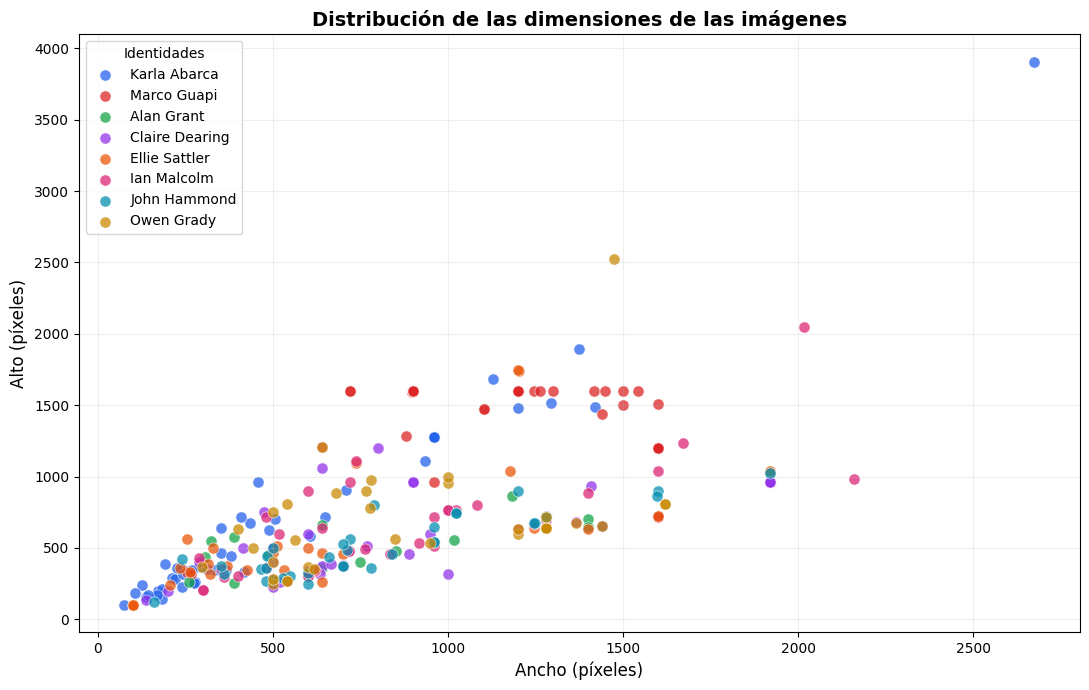

In [7]:
# Distribución de las dimensiones por identidad

plt.figure(figsize=(11, 7))

colores = [
    "#2563EB",  # Azul
    "#DC2626",  # Rojo
    "#16A34A",  # Verde
    "#9333EA",  # Morado
    "#EA580C",  # Naranja
    "#DB2777",  # Rosa
    "#0891B2",  # Turquesa
    "#CA8A04"   # Mostaza
]

for (persona, grupo), color in zip(df.groupby("Persona"), colores):
    plt.scatter(
        grupo["Ancho"],
        grupo["Alto"],
        label=persona.replace("_", " ").title(),
        color=color,
        alpha=0.75,
        edgecolors="white",
        linewidth=0.5,
        s=65
    )

plt.title("Distribución de las dimensiones de las imágenes",
          fontsize=14, fontweight="bold")

plt.xlabel("Ancho (píxeles)", fontsize=12)
plt.ylabel("Alto (píxeles)", fontsize=12)

plt.legend(title="Identidades", loc="upper left")
plt.grid(alpha=0.20)
plt.tight_layout()

plt.savefig("eda_dimensiones_imagenes.png",
            dpi=300, bbox_inches="tight")

plt.show()

## Análisis de la detección facial

Se analiza la cantidad de rostros detectados en cada 
fotografía mediante el método HOG, con el propósito de 
identificar posibles dificultades durante la preparación 
de la galería de referencia.

In [8]:
import face_recognition

cantidad_rostros = []

for ruta in df["Ruta"]:
    imagen = cv2.imread(ruta)

    if imagen is not None:
        rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

        rostros = face_recognition.face_locations(
            rgb, model="hog"
        )

        cantidad_rostros.append(len(rostros))
    else:
        cantidad_rostros.append(np.nan)

df["Rostros_detectados"] = cantidad_rostros

# Clasificar las imágenes según la detección
df["Estado_deteccion"] = df["Rostros_detectados"].apply(
    lambda x: "Sin rostro" if x == 0 else
    "Un rostro" if x == 1 else
    "Múltiples rostros" if x > 1 else
    "Imagen no legible"
)

# Resumen de los resultados
resumen = df["Estado_deteccion"].value_counts()

display(resumen.to_frame("Cantidad de imágenes"))

C:\Users\Usuario\Desktop\MAESTRIA EN IA\HERRAMIENTAS EN IA\entorno01\Lib\site-packages\face_recognition_models\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


,Cantidad de imágenes
Estado_deteccion,
Un rostro,256
Sin rostro,66
Múltiples rostros,7


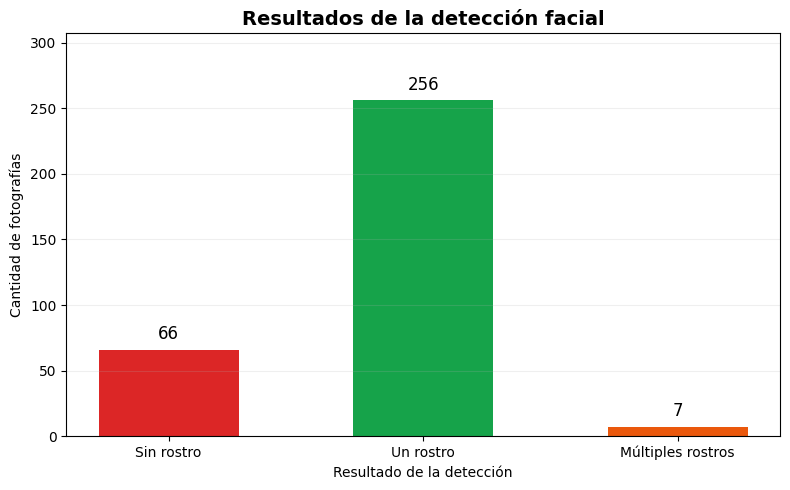

In [9]:
categorias = ["Sin rostro", "Un rostro", "Múltiples rostros"]

resumen = df["Estado_deteccion"].value_counts().reindex(
    categorias, fill_value=0
)

plt.figure(figsize=(8, 5))

barras = plt.bar(
    resumen.index,
    resumen.values,
    color=["#DC2626", "#16A34A", "#EA580C"],
    width=0.55
)

plt.bar_label(barras, padding=5, fontsize=12)

plt.title("Resultados de la detección facial",
          fontsize=14, fontweight="bold")

plt.ylabel("Cantidad de fotografías")
plt.xlabel("Resultado de la detección")
plt.ylim(0, resumen.max() * 1.20)
plt.grid(axis="y", alpha=0.20)
plt.tight_layout()

plt.savefig("eda_deteccion_facial.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [10]:
# Verificar las imágenes con múltiples rostros
display(df[df["Rostros_detectados"] > 1][
    ["Persona", "Archivo", "Rostros_detectados"]
])

print("Total de rostros detectados:",
      int(df["Rostros_detectados"].sum()))

,Persona,Archivo,Rostros_detectados
47,claire_dearing,00000028.png,2
57,claire_dearing,00000043.png,2
70,claire_dearing,00000076.jpg,2
264,Marco_Guapi,WhatsApp Image 2026-10-15 at 08.00.31 (28).jpeg,2
309,owen_grady,00000018.jpg,2
321,owen_grady,00000041.jpg,2
324,owen_grady,00000068.jpg,2


Total de rostros detectados: 270


## Distribución de las codificaciones faciales

Se compara la cantidad de fotografías originales con las 
codificaciones faciales almacenadas en la galería de 
referencia para conocer la representación de cada identidad.

In [11]:
import pickle

# Cargar las codificaciones existentes
with open("encodings.pickle", "rb") as archivo:
    datos = pickle.load(archivo)

# Cantidad de fotografías por identidad
fotografias = df["Persona"].value_counts()

# Cantidad de codificaciones por identidad
codificaciones = pd.Series(datos["names"]).value_counts()

# Comparar ambas cantidades
comparacion = pd.DataFrame({
    "Fotografías": fotografias,
    "Codificaciones": codificaciones
}).fillna(0).astype(int)

comparacion = comparacion.sort_index()

display(comparacion)

print("Total de fotografías:", comparacion["Fotografías"].sum())
print("Total de codificaciones:", comparacion["Codificaciones"].sum())

,Fotografías,Codificaciones
Karla_Abarca,53,40
Marco_Guapi,58,51
alan_grant,22,12
claire_dearing,53,46
ellie_sattler,31,29
ian_malcolm,41,39
john_hammond,36,18
owen_grady,35,35


Total de fotografías: 329
Total de codificaciones: 270


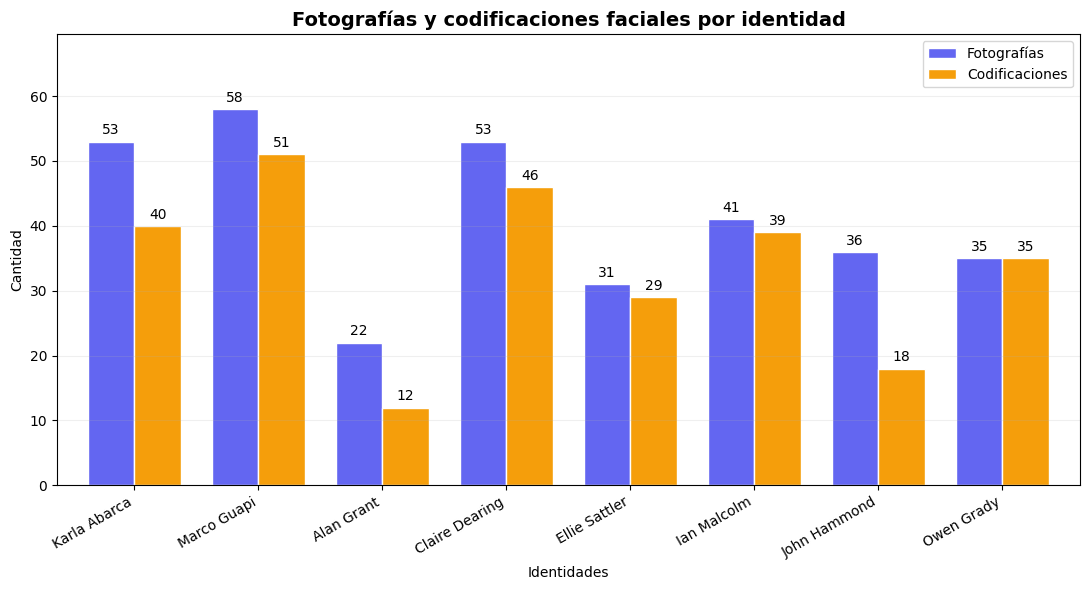

In [12]:
# Comparación de fotografías y codificaciones

ax = comparacion.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#6366F1", "#F59E0B"],
    width=0.75,
    edgecolor="white"
)

for barras in ax.containers:
    ax.bar_label(barras, padding=3, fontsize=10)

plt.title("Fotografías y codificaciones faciales por identidad",
          fontsize=14, fontweight="bold")

plt.xlabel("Identidades")
plt.ylabel("Cantidad")

plt.xticks(
    range(len(comparacion)),
    [nombre.replace("_", " ").title()
     for nombre in comparacion.index],
    rotation=30,
    ha="right"
)

plt.legend()
plt.ylim(0, comparacion.to_numpy().max() * 1.20)
plt.grid(axis="y", alpha=0.20)
plt.tight_layout()

plt.savefig("eda_comparacion_codificaciones.png",
            dpi=300, bbox_inches="tight")

plt.show()